# Customer Churn Prediction – Machine Learning Project

**Goal:** Predict whether a telecom customer is likely to leave the service (`Churn = Yes`).

**Dataset:** IBM Telco Customer Churn (7,043 customer records; target column: `Churn`).

**Workflow:** Understand data → clean data → EDA → preprocessing → train/test split → model training → evaluation → model comparison → feature importance → save best model.

> Keep `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the same folder as this notebook. If your file has a different name, update `DATA_PATH` in Cell 2.

## 1. Import required libraries
We use Pandas and NumPy for data handling, Matplotlib/Seaborn for visualization, and Scikit-learn for machine learning.

In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the dataset
Place the CSV file beside this notebook. This cell checks that the file exists before loading it.

In [13]:
import pandas as pd
from pathlib import Path
import urllib.request

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")

urllib.request.urlretrieve(url, DATA_PATH)

print("Dataset downloaded successfully!")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the dataset
Check the number of rows and columns, column names, data types, and sample records.

In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nColumn names:")
print(df.columns.tolist())

display(df.info())
display(df.head(10))

Rows: 7043
Columns: 21
\nColumn names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7

None

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


## 4. Data quality checks
Check missing values, duplicate rows, and duplicate customer IDs. `TotalCharges` is often stored as text even though it represents a number.

In [15]:
print("Missing values before cleaning:")
display(df.isnull().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())
if "customerID" in df.columns:
    print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\\nData types:")
display(df.dtypes)

Missing values before cleaning:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0
\nData types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

## 5. Clean the data
Convert `TotalCharges` to numeric. Blank strings become missing values. Remove exact duplicate rows, if any.

In [16]:
df = df.copy()

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.drop_duplicates().copy()

print("Shape after removing exact duplicates:", df.shape)
print("Missing values after conversion:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Shape after removing exact duplicates: (7043, 21)
Missing values after conversion:


TotalCharges    11
dtype: int64

## 6. Target variable and class distribution
The target is `Churn`. We convert Yes/No into 1/0 for evaluation. First inspect the original class balance.

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

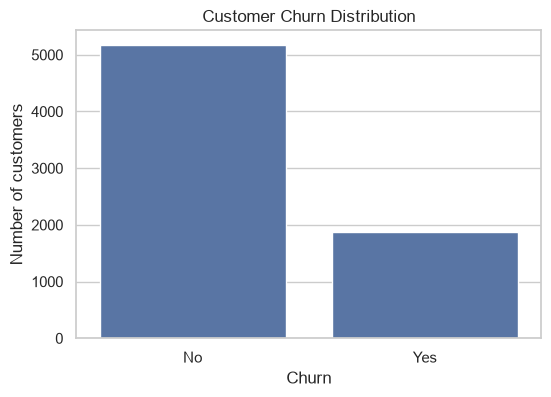

In [17]:
if "Churn" not in df.columns:
    raise ValueError("Target column 'Churn' was not found. Check your dataset.")

display(df["Churn"].value_counts(dropna=False))
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.show()

## 7. Exploratory Data Analysis (EDA)
Explore churn by contract type, tenure, and monthly charges. These are descriptive patterns, not proof of causation.

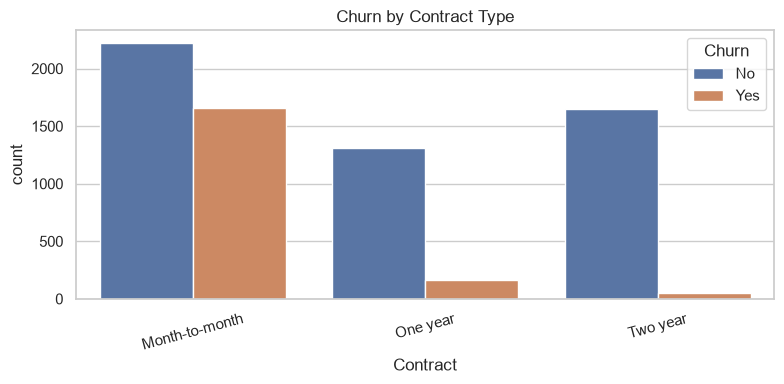

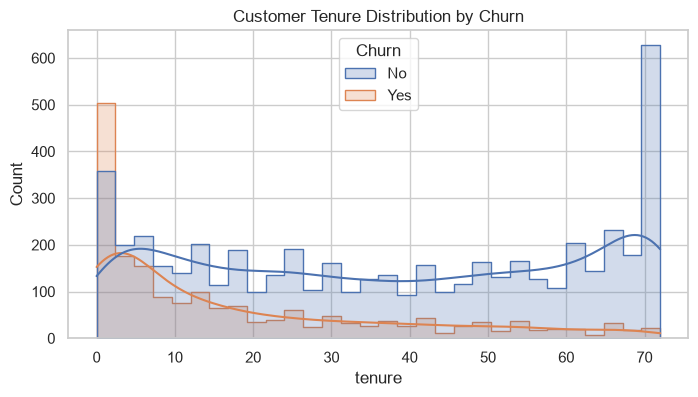

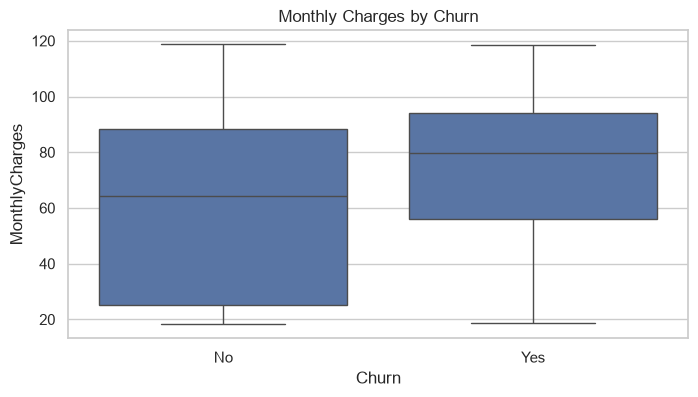

In [18]:
if "Contract" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x="Contract", hue="Churn")
    plt.title("Churn by Contract Type")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

if "tenure" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, element="step")
    plt.title("Customer Tenure Distribution by Churn")
    plt.show()

if "MonthlyCharges" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.title("Monthly Charges by Churn")
    plt.show()

## 8. Prepare features and target
`customerID` is an identifier, so it is excluded from model training. The target is mapped to 1 for Yes and 0 for No.

In [19]:
data = df.copy()

# Remove identifier because it does not describe customer behavior.
if "customerID" in data.columns:
    data = data.drop(columns=["customerID"])

data = data.dropna(subset=["Churn"]).copy()
y = data["Churn"].map({"Yes": 1, "No": 0})

if y.isna().any():
    raise ValueError("Unexpected values found in Churn. Inspect data['Churn'].unique().")

X = data.drop(columns=["Churn"])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique()))
display(X.head())

Feature matrix shape: (7043, 19)
Target shape: (7043,)
Target values: [np.int64(0), np.int64(1)]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


## 9. Identify numerical and categorical columns
The preprocessing steps are selected automatically based on column data types.

In [20]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 10. Train-test split
Use a stratified split so the churn/non-churn proportions remain similar in training and test sets. The test set is held back for final evaluation.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("\\nChurn rate in training set:", round(y_train.mean(), 3))
print("Churn rate in test set:", round(y_test.mean(), 3))

X_train: (5634, 19)
X_test : (1409, 19)
\nChurn rate in training set: 0.265
Churn rate in test set: 0.265


## 11. Build preprocessing pipeline
Numerical columns: median imputation + scaling. Categorical columns: most-frequent imputation + one-hot encoding. `handle_unknown='ignore'` safely handles categories that appear only in test/new data.

In [22]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## 12. Create machine learning models
We compare Logistic Regression, Decision Tree, and Random Forest. Class weighting helps models pay attention to the smaller churn class.

In [23]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, max_depth=6
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

## 13. Train and evaluate each model
Each model includes preprocessing inside a Scikit-learn Pipeline. This helps prevent preprocessing leakage between training and test data.

In [24]:
fitted_models = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    results.append(row)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
1,Decision Tree,0.7410,0.5077,0.7914,0.6186,0.8290
2,Random Forest,0.7658,0.5521,0.6230,0.5854,0.8218


## 14. Compare model performance
ROC-AUC measures how well the model ranks churners above non-churners. Recall is also important when the business wants to identify as many potential churners as possible.

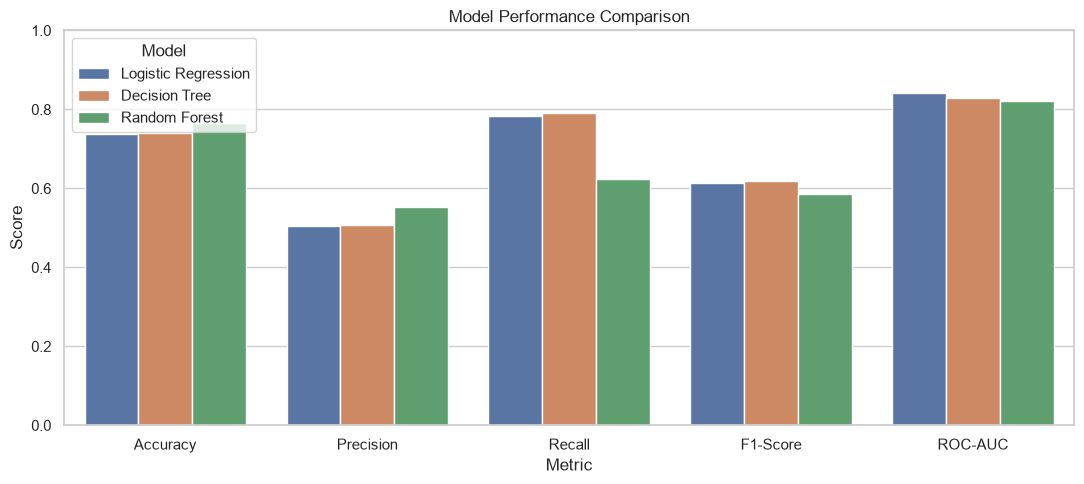

In [25]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_long = results_df.melt(
    id_vars="Model", value_vars=metrics_to_plot,
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=results_long, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1)
plt.title("Model Performance Comparison")
plt.tight_layout()
plt.show()

## 15. Select the best model
For this notebook, select the model with the highest test ROC-AUC. In a real project, choose the metric that best matches the business objective and validate the choice with cross-validation.

In [26]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Selected model:", best_model_name)

Selected model: Logistic Regression


## 16. Detailed evaluation of the selected model
Review the classification report and confusion matrix. Pay particular attention to churn-class recall and precision.

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



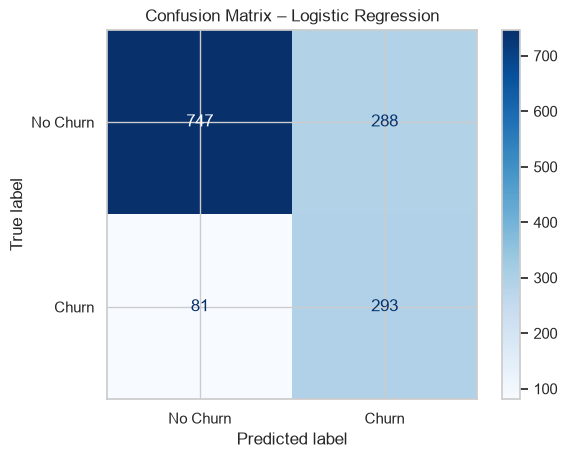

In [27]:
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, best_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix – {best_model_name}")
plt.show()

## 17. ROC curve
The ROC curve shows the trade-off between true-positive rate and false-positive rate across classification thresholds.

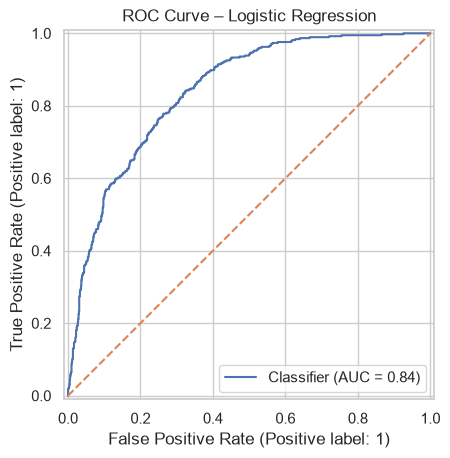

Test ROC-AUC: 0.8413


In [28]:
RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title(f"ROC Curve – {best_model_name}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.show()

print("Test ROC-AUC:", round(roc_auc_score(y_test, best_prob), 4))

## 18. Cross-validation on the training data
Cross-validation estimates how consistently the model performs across different training folds. The held-out test set remains separate.

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = cross_val_score(
    best_model, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

print("5-Fold CV ROC-AUC scores:", np.round(cv_scores, 4))
print("Mean CV ROC-AUC:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

5-Fold CV ROC-AUC scores: [0.8471 0.8255 0.8416 0.8626 0.853 ]
Mean CV ROC-AUC: 0.8459
Standard deviation: 0.0124


## 19. Feature importance (tree-based models)
For Random Forest or Decision Tree, inspect the most influential transformed features. For Logistic Regression, coefficients can be examined separately.

In [30]:
final_estimator = best_model.named_steps["model"]
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

if hasattr(final_estimator, "feature_importances_"):
    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": final_estimator.feature_importances_
    }).sort_values("Importance", ascending=False).head(15)

    display(importance)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=importance, x="Importance", y="Feature")
    plt.title("Top 15 Feature Importances")
    plt.tight_layout()
    plt.show()
else:
    print("The selected model does not provide tree-based feature_importances_.")

The selected model does not provide tree-based feature_importances_.


## 20. Predict churn for a sample customer
This example uses an existing test record so the feature columns and data types match the training data. The probability is the model's estimated churn probability, not a guarantee.

In [31]:
sample_customer = X_test.iloc[[0]]
sample_probability = best_model.predict_proba(sample_customer)[0, 1]
sample_prediction = best_model.predict(sample_customer)[0]

print("Predicted class:", "Churn" if sample_prediction == 1 else "No Churn")
print("Estimated churn probability:", f"{sample_probability:.2%}")
display(sample_customer)

Predicted class: No Churn
Estimated churn probability: 11.55%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


## 21. Save the trained model
The saved Pipeline includes preprocessing and the trained estimator. Use the same feature columns when loading it for future predictions.

In [32]:
import joblib

MODEL_PATH = "customer_churn_pipeline.joblib"
joblib.dump(best_model, MODEL_PATH)
print("Model saved to:", MODEL_PATH)

Model saved to: customer_churn_pipeline.joblib


## 22. Project conclusion

In this project, we built a customer churn classification workflow using the IBM Telco Customer Churn dataset.

- Inspected and cleaned customer data.
- Explored churn patterns using visualizations.
- Built preprocessing with imputation, scaling, and one-hot encoding.
- Trained and compared Logistic Regression, Decision Tree, and Random Forest.
- Evaluated models using Accuracy, Precision, Recall, F1-Score, ROC-AUC, confusion matrix, and cross-validation.
- Saved the selected end-to-end pipeline.

**Important:** Use the actual scores printed by your notebook in your resume. Do not copy sample metrics from another run, because results can vary with preprocessing, split, and model settings.